In [ ]:
#11/23 작업

In [ ]:

from pathlib import Path
import math
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==========================================
# 1. Settings
# ==========================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

Z_DIR = BASE_DIR / "PR_zscore_pooled5"

SCENARIOS = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

TITLES = [
    "45°N", "30°N", "15°N", "0°",
    "15°S", "30°S", "45°S"
]

MEMBERS = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

SEASONS = ["DJF", "MAM", "JJA", "SON"]

VMIN, VMAX = -1.0, 1.0
HATCH_AGREEMENT = 2 / 3

# Reference statistics:
# SSP245 r1-r5, pooled across member and year
# Standard deviation calculated with ddof=1
#
# DJF: 5 x 29 = 145 samples
# MAM/JJA/SON: 5 x 30 = 150 samples

plt.rcParams["hatch.linewidth"] = 0.4
plt.rcParams["hatch.color"] = "#333333"

# ==========================================
# 2. Common spatial mask
# ==========================================

mask_candidates = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy",
]

mask_path = next(
    (p for p in mask_candidates if p.exists()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found"
    )

valid_mask = np.load(mask_path).astype(bool)

assert valid_mask.shape == (192, 288)

print("Mask:", mask_path)
print("Valid cells:", valid_mask.sum())

# ==========================================
# 3. Reference grid
# ==========================================

reference_file = (
    BASE_DIR / "PR_SSP_ymonmean_pooled5.nc"
)

with xr.open_dataset(reference_file) as ds:
    lats = ds["lat"].values.copy()
    lons = ds["lon"].values.copy()

GRID_SHAPE = (len(lats), len(lons))

assert GRID_SHAPE == valid_mask.shape

# ==========================================
# 4. Load individual SAI z-scores
# ==========================================

def load_member_zscore(scenario, member):

    path = Z_DIR / (
        f"PR_zscore_yseasmean_"
        f"{scenario}_{member}.nc"
    )

    if not path.is_file():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        da = ds["pr"].transpose(
            "time", "lat", "lon"
        )

        np.testing.assert_allclose(
            da["lat"].values, lats
        )

        np.testing.assert_allclose(
            da["lon"].values, lons
        )

        labels = np.asarray(
            da.time.dt.season.values
        )

        if len(labels) != 4:
            raise ValueError(
                f"Expected 4 seasons: {path}"
            )

        indices = []

        for season in SEASONS:

            matches = np.where(
                labels == season
            )[0]

            if len(matches) != 1:
                raise ValueError(
                    f"Invalid {season}: {path}"
                )

            indices.append(matches[0])

        values = da.values[indices].copy()

    values[~np.isfinite(values)] = np.nan

    if values.shape != (4, *GRID_SHAPE):
        raise ValueError(
            f"Unexpected shape: {values.shape}"
        )

    return values

# ==========================================
# 5. Create 4 x 7 figure
# ==========================================

fig, axes = plt.subplots(
    4, 7,
    figsize=(28, 13),
    dpi=300,
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    },
    constrained_layout=True
)

fig.suptitle(
    "Seasonal Precipitation Z-score "
    "across SAI Injection Scenarios "
    "(2040–2069 vs SSP2-4.5)",
    fontsize=22,
    fontweight="bold",
    y=1.03
)

diagnostics = []
im = None

# ==========================================
# 6. Process each injection scenario
# ==========================================

for col, scenario in enumerate(SCENARIOS):

    # Individual member z-score:
    # shape = (6, 4, 192, 288)
    stack = np.stack(
        [
            load_member_zscore(scenario, member)
            for member in MEMBERS
        ],
        axis=0
    )

    n_members = stack.shape[0]

    min_agreement = math.ceil(
        HATCH_AGREEMENT * n_members
    )

    for row, season in enumerate(SEASONS):

        ax = axes[row, col]

        member_z = stack[:, row, :, :]

        # ----------------------------------
        # 7. Ensemble mean of individual z
        # ----------------------------------

        valid_count = np.sum(
            np.isfinite(member_z),
            axis=0
        )

        ensemble_mean = np.divide(
            np.nansum(member_z, axis=0),
            valid_count,
            out=np.full(GRID_SHAPE, np.nan),
            where=valid_count > 0
        )

        # ----------------------------------
        # 8. Member-wise sign agreement
        # ----------------------------------

        positive = np.sum(
            member_z > 0,
            axis=0
        )

        negative = np.sum(
            member_z < 0,
            axis=0
        )

        # 4 or more of 6 members must
        # have the same anomaly sign.
        # All members must be valid.
        all_valid = (
            valid_count == n_members
        )

        hatch_mask = (
            (np.maximum(positive, negative)
             >= min_agreement)
            & all_valid
            & valid_mask
        )

        # ----------------------------------
        # 9. Apply spatial mask
        # ----------------------------------

        plotted_z = np.where(
            valid_mask,
            ensemble_mean,
            np.nan
        )

        # Only the displayed values are
        # clipped; diagnostics use raw z.
        clipped_z = np.clip(
            plotted_z, VMIN, VMAX
        )

        # ----------------------------------
        # 10. Map
        # ----------------------------------

        im = ax.pcolormesh(
            lons,
            lats,
            clipped_z,
            transform=ccrs.PlateCarree(),
            cmap="BrBG",
            vmin=VMIN,
            vmax=VMAX,
            shading="auto",
            rasterized=True
        )

        ax.contourf(
            lons,
            lats,
            hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=["///"],
            colors="none",
            transform=ccrs.PlateCarree()
        )

        ax.add_feature(
            cfeature.COASTLINE,
            linewidth=0.5,
            edgecolor="black"
        )

        ax.set_global()

        if row == 0:
            ax.set_title(
                f"SAI {TITLES[col]}",
                fontsize=15,
                fontweight="bold",
                pad=10
            )

        if col == 0:
            ax.text(
                -0.15, 0.5, season,
                transform=ax.transAxes,
                fontsize=16,
                fontweight="bold",
                va="center",
                rotation=90
            )

        # ----------------------------------
        # 11. Diagnostics
        # ----------------------------------

        # A. Ensemble-mean map grid ratio
        map_values = plotted_z[
            np.isfinite(plotted_z)
        ]

        map_within_1 = (
            np.mean(np.abs(map_values) <= 1)
            * 100
            if map_values.size else np.nan
        )

        # B. Individual-member grid ratio
        # This is different from A.
        member_values = member_z[
            :,
            valid_mask
        ]

        member_values = member_values[
            np.isfinite(member_values)
        ]

        member_within_1 = (
            np.mean(np.abs(member_values) <= 1)
            * 100
            if member_values.size else np.nan
        )

        map_outside_3 = (
            np.mean(np.abs(map_values) > 3)
            * 100
            if map_values.size else np.nan
        )

        hatch_coverage = (
            np.sum(hatch_mask)
            / np.sum(valid_mask)
            * 100
        )

        diagnostics.append({
            "scenario": scenario,
            "season": season,
            "map_within_1": map_within_1,
            "member_within_1": member_within_1,
            "map_outside_3": map_outside_3,
            "hatch_coverage": hatch_coverage
        })

        print(
            f"{scenario:>3} {season}: "
            f"map |z|<=1 {map_within_1:5.1f}% | "
            f"member |z|<=1 "
            f"{member_within_1:5.1f}% | "
            f"map |z|>3 "
            f"{map_outside_3:5.1f}% | "
            f"hatch {hatch_coverage:5.1f}%"
        )

# ==========================================
# 12. Colorbar
# ==========================================

cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    shrink=0.45,
    aspect=35,
    pad=0.03,
    extend="both"
)

cbar.set_label(
    "Seasonal Precipitation Z-score "
    "(SAI Ensemble Mean)",
    fontsize=15,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=12)

# ==========================================
# 13. Caption
# ==========================================

fig.text(
    0.5,
    -0.01,
    "SSP245 reference: pooled r1-r5 "
    "(member × year, sample SD, ddof=1). "
    "Hatching: at least 4 of 6 SAI members "
    "agree on anomaly sign.",
    ha="center",
    fontsize=12,
    fontstyle="italic",
    color="#333333"
)

# ==========================================
# 14. Save
# ==========================================

output_path = (
    BASE_DIR
    / "PR_4x7_pooled5_professor_feedback.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", output_path)

# ==========================================
# 15. Overall diagnostics
# ==========================================

print("\n===== Overall diagnostics =====")

for key, description in [
    ("map_within_1", "Map |z| <= 1"),
    ("member_within_1", "Member |z| <= 1"),
    ("map_outside_3", "Map |z| > 3"),
    ("hatch_coverage", "Hatched area")
]:

    values = [
        item[key]
        for item in diagnostics
    ]

    print(
        f"{description}: "
        f"{np.nanmean(values):.1f}%"
    )


Mask: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Valid grid cells: 11856

SAI 45N: 6 members (e02, e03, e04, e05, e06, e07), hatching >= 4
45N DJF: map |z|<=1  51.4% | member |z|<=1  51.3% | map |z|>3  11.9% | hatch  98.2%
45N MAM: map |z|<=1  45.5% | member |z|<=1  45.7% | map |z|>3   7.8% | hatch  98.3%
45N JJA: map |z|<=1  40.5% | member |z|<=1  40.4% | map |z|>3  13.6% | hatch  98.6%
45N SON: map |z|<=1  46.2% | member |z|<=1  46.1% | map |z|>3  14.3% | hatch  98.3%

SAI 30N: 6 members (e02, e03, e04, e05, e06, e07), hatching >= 4
30N DJF: map |z|<=1  54.3% | member |z|<=1  53.8% | map |z|>3  11.9% | hatch  97.9%
30N MAM: map |z|<=1  50.4% | member |z|<=1  50.4% | map |z|>3   7.1% | hatch  98.0%
30N JJA: map |z|<=1  43.8% | member |z|<=1  43.7% | map |z|>3  11.2% | hatch  98.2%
30N SON: map |z|<=1  48.6% | member |z|<=1  48.4% | map |z|>3  13.5% | hatch  98.0%
Missing member: 15N_e05 (skipped)

SAI 15N: 5 members (e02, e03, e04, e06, e07), hatching >= 4
15N DJF:

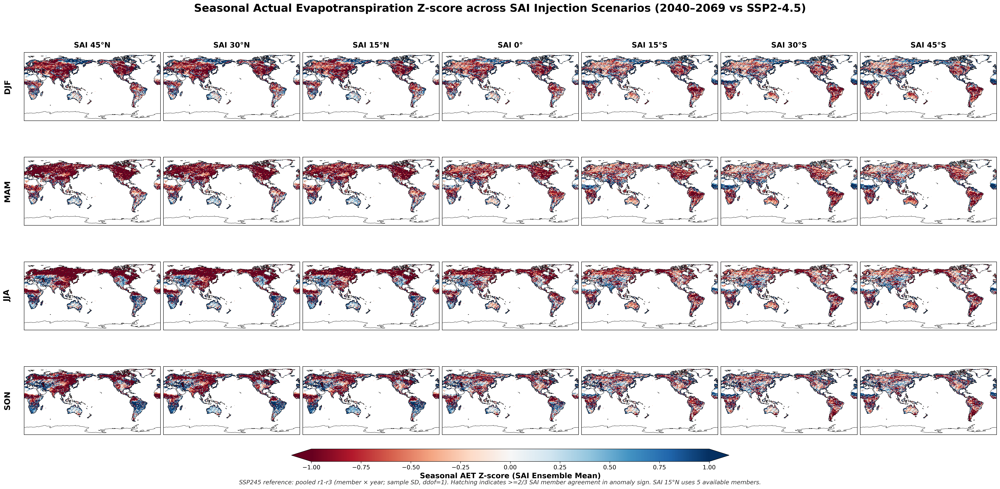


Map generation completed.
Saved to: C:\Users\soyoo\URP_cdo_data\10~11\1118\AET_4x7_pooled3_professor_feedback.png

===== Overall diagnostics =====
Map |z| <= 1: 57.2%
Member |z| <= 1: 56.8%
Map |z| > 3: 10.4%
Hatched area: 97.2%


In [7]:

from pathlib import Path
import math
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==========================================
# 1. Settings
# ==========================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

Z_DIR = BASE_DIR / "AET_zscore_pooled3"

SCENARIOS = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

TITLES = [
    "45°N", "30°N", "15°N", "0°",
    "15°S", "30°S", "45°S"
]

MEMBERS = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

SEASONS = ["DJF", "MAM", "JJA", "SON"]

VMIN = -1.0
VMAX = 1.0

HATCH_AGREEMENT = 2 / 3

# SSP245 reference:
# r1-r3 pooled across member and year.
# Sample standard deviation: ddof=1.
#
# DJF: 3 x 29 = 87 samples
# MAM/JJA/SON: 3 x 30 = 90 samples

plt.rcParams["hatch.linewidth"] = 0.4
plt.rcParams["hatch.color"] = "#333333"

# ==========================================
# 2. Load common spatial mask
# ==========================================

mask_candidates = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy",
]

mask_path = next(
    (p for p in mask_candidates if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found "
        "in 1118 or 1115."
    )

valid_mask = np.load(mask_path).astype(bool)

assert valid_mask.shape == (192, 288), (
    f"Unexpected mask shape: {valid_mask.shape}"
)

print("Mask:", mask_path)
print("Valid grid cells:", valid_mask.sum())

# ==========================================
# 3. Load SSP245 reference grid
# ==========================================

reference_file = (
    BASE_DIR / "AET_SSP_ymonmean_pooled3.nc"
)

with xr.open_dataset(reference_file) as ds:
    lats = ds["lat"].values.copy()
    lons = ds["lon"].values.copy()

GRID_SHAPE = (len(lats), len(lons))

assert GRID_SHAPE == valid_mask.shape

# ==========================================
# 4. Load individual SAI AET z-scores
# ==========================================

def load_member_zscore(scenario, member):

    path = Z_DIR / (
        f"AET_zscore_yseasmean_"
        f"{scenario}_{member}.nc"
    )

    if not path.is_file():
        return None

    with xr.open_dataset(path) as ds:

        if "aet" not in ds:
            raise ValueError(
                f"Variable 'aet' missing: {path}"
            )

        da = ds["aet"].transpose(
            "time", "lat", "lon"
        )

        np.testing.assert_allclose(
            da["lat"].values,
            lats,
            err_msg=f"Latitude mismatch: {path}"
        )

        np.testing.assert_allclose(
            da["lon"].values,
            lons,
            err_msg=f"Longitude mismatch: {path}"
        )

        labels = np.asarray(
            da.time.dt.season.values
        )

        if len(labels) != 4:
            raise ValueError(
                f"Expected 4 seasons: {path}"
            )

        indices = []

        for season in SEASONS:

            matches = np.where(
                labels == season
            )[0]

            if len(matches) != 1:
                raise ValueError(
                    f"Invalid season {season}: {path}"
                )

            indices.append(matches[0])

        values = da.values[indices].copy()

    values[~np.isfinite(values)] = np.nan

    if values.shape != (4, *GRID_SHAPE):
        raise ValueError(
            f"Unexpected shape: {values.shape}"
        )

    return values

# ==========================================
# 5. Create figure
# ==========================================

fig, axes = plt.subplots(
    nrows=4,
    ncols=7,
    figsize=(28, 13),
    dpi=300,
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    },
    constrained_layout=True
)

fig.suptitle(
    "Seasonal Actual Evapotranspiration "
    "Z-score across SAI Injection Scenarios "
    "(2040–2069 vs SSP2-4.5)",
    fontsize=22,
    fontweight="bold",
    y=1.03
)

diagnostics = []
im = None

# ==========================================
# 6. Process each injection scenario
# ==========================================

for col, scenario in enumerate(SCENARIOS):

    member_arrays = []
    loaded_members = []

    for member in MEMBERS:

        z_arr = load_member_zscore(
            scenario, member
        )

        if z_arr is None:
            print(
                f"Missing member: "
                f"{scenario}_{member} (skipped)"
            )
            continue

        member_arrays.append(z_arr)
        loaded_members.append(member)

    if not member_arrays:
        raise ValueError(
            f"No available members: {scenario}"
        )

    # Shape:
    # Usually (6, 4, 192, 288)
    # 15N may have (5, 4, 192, 288)
    stack = np.stack(
        member_arrays, axis=0
    )

    n_members = stack.shape[0]

    min_agreement = math.ceil(
        HATCH_AGREEMENT * n_members
    )

    print(
        f"\nSAI {scenario}: "
        f"{n_members} members "
        f"({', '.join(loaded_members)}), "
        f"hatching >= {min_agreement}"
    )

    # ======================================
    # 7. Seasonal maps
    # ======================================

    for row, season in enumerate(SEASONS):

        ax = axes[row, col]

        member_z = stack[:, row, :, :]

        # ----------------------------------
        # 8. Ensemble mean of individual z
        # ----------------------------------

        valid_count = np.sum(
            np.isfinite(member_z),
            axis=0
        )

        ensemble_mean = np.divide(
            np.nansum(member_z, axis=0),
            valid_count,
            out=np.full(
                GRID_SHAPE, np.nan
            ),
            where=valid_count > 0
        )

        # ----------------------------------
        # 9. Member-wise sign agreement
        # ----------------------------------

        positive = np.sum(
            member_z > 0,
            axis=0
        )

        negative = np.sum(
            member_z < 0,
            axis=0
        )

        all_valid = (
            valid_count == n_members
        )

        hatch_mask = (
            (
                np.maximum(positive, negative)
                >= min_agreement
            )
            & all_valid
            & valid_mask
        )

        # ----------------------------------
        # 10. Apply common spatial mask
        # ----------------------------------

        plotted_z = np.where(
            valid_mask,
            ensemble_mean,
            np.nan
        )

        # Clipping only affects the display.
        clipped_z = np.clip(
            plotted_z,
            VMIN,
            VMAX
        )

        # ----------------------------------
        # 11. Draw map
        # ----------------------------------

        im = ax.pcolormesh(
            lons,
            lats,
            clipped_z,
            transform=ccrs.PlateCarree(),
            cmap="RdBu",
            vmin=VMIN,
            vmax=VMAX,
            shading="auto",
            rasterized=True
        )

        ax.contourf(
            lons,
            lats,
            hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=["///"],
            colors="none",
            transform=ccrs.PlateCarree()
        )

        ax.add_feature(
            cfeature.COASTLINE,
            linewidth=0.5,
            edgecolor="black"
        )

        ax.set_global()

        # Injection latitude
        if row == 0:
            ax.set_title(
                f"SAI {TITLES[col]}",
                fontsize=15,
                fontweight="bold",
                pad=10
            )

        # Season label
        if col == 0:
            ax.text(
                -0.15,
                0.5,
                season,
                transform=ax.transAxes,
                fontsize=16,
                fontweight="bold",
                va="center",
                rotation=90
            )

        # ----------------------------------
        # 12. Diagnostics
        # ----------------------------------

        # A. Ensemble-mean map grid ratio
        map_values = plotted_z[
            np.isfinite(plotted_z)
        ]

        map_within_1 = (
            np.mean(
                np.abs(map_values) <= 1
            ) * 100
            if map_values.size else np.nan
        )

        map_outside_3 = (
            np.mean(
                np.abs(map_values) > 3
            ) * 100
            if map_values.size else np.nan
        )

        # B. Individual-member grid ratio
        member_values = member_z[
            :, valid_mask
        ]

        member_values = member_values[
            np.isfinite(member_values)
        ]

        member_within_1 = (
            np.mean(
                np.abs(member_values) <= 1
            ) * 100
            if member_values.size else np.nan
        )

        # C. Hatching coverage
        hatch_coverage = (
            np.sum(hatch_mask)
            / np.sum(valid_mask)
            * 100
        )

        diagnostics.append({
            "scenario": scenario,
            "season": season,
            "n_members": n_members,
            "map_within_1": map_within_1,
            "member_within_1": member_within_1,
            "map_outside_3": map_outside_3,
            "hatch_coverage": hatch_coverage
        })

        print(
            f"{scenario:>3} {season}: "
            f"map |z|<=1 "
            f"{map_within_1:5.1f}% | "
            f"member |z|<=1 "
            f"{member_within_1:5.1f}% | "
            f"map |z|>3 "
            f"{map_outside_3:5.1f}% | "
            f"hatch "
            f"{hatch_coverage:5.1f}%"
        )

# ==========================================
# 13. Colorbar
# ==========================================

cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    shrink=0.45,
    aspect=35,
    pad=0.03,
    extend="both"
)

cbar.set_label(
    "Seasonal AET Z-score "
    "(SAI Ensemble Mean)",
    fontsize=15,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=12)

# ==========================================
# 14. Caption
# ==========================================

fig.text(
    0.5,
    -0.01,
    "SSP245 reference: pooled r1-r3 "
    "(member × year; sample SD, ddof=1). "
    "Hatching indicates >=2/3 SAI member "
    "agreement in anomaly sign. "
    "SAI 15°N uses 5 available members.",
    ha="center",
    fontsize=12,
    fontstyle="italic",
    color="#333333"
)

# ==========================================
# 15. Save figure
# ==========================================

output_path = (
    BASE_DIR
    / "AET_4x7_pooled3_professor_feedback.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMap generation completed.")
print("Saved to:", output_path)

# ==========================================
# 16. Overall diagnostics
# ==========================================

print("\n===== Overall diagnostics =====")

for key, description in [
    ("map_within_1", "Map |z| <= 1"),
    ("member_within_1", "Member |z| <= 1"),
    ("map_outside_3", "Map |z| > 3"),
    ("hatch_coverage", "Hatched area")
]:

    values = [
        item[key]
        for item in diagnostics
    ]

    print(
        f"{description}: "
        f"{np.nanmean(values):.1f}%"
    )


In [8]:

from pathlib import Path
import numpy as np
import xarray as xr

BASE = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

mask_path = BASE / "common_spatial_mask.npy"
if not mask_path.exists():
    mask_path = BASE.parent / "1115" / "common_spatial_mask.npy"

mask = np.load(mask_path).astype(bool)

seasons = ["DJF", "MAM", "JJA", "SON"]
members = ["e02", "e03", "e04", "e05", "e06", "e07"]

for var, folder, ref in [
    ("PR", "PR_zscore_pooled5", "PR_SSP_ymonmean_pooled5.nc"),
    ("AET", "AET_zscore_pooled3", "AET_SSP_ymonmean_pooled3.nc"),
]:
    with xr.open_dataset(BASE / ref) as ds:
        lat = ds.lat.values

    # Area-weighted land-cell mean
    weights = np.cos(np.deg2rad(lat))[:, None] * np.ones(mask.shape)

    print(f"\n========== {var} ==========")

    for scenario in ["45N", "45S"]:
        arrays = []

        for member in members:
            path = BASE / folder / (
                f"{var}_zscore_yseasmean_{scenario}_{member}.nc"
            )

            with xr.open_dataset(path) as ds:
                da = ds[var.lower()].transpose("time", "lat", "lon")
                labels = da.time.dt.season.values
                idx = [np.where(labels == s)[0][0] for s in seasons]
                arrays.append(da.values[idx])

        mean_z = np.mean(np.stack(arrays), axis=0)

        for hemisphere, lat_region in [
            ("NH", lat > 0),
            ("SH", lat < 0),
        ]:
            region = mask & lat_region[:, None]

            for i, season in enumerate(seasons):
                values = mean_z[i]
                valid = region & np.isfinite(values)

                w = weights[valid]
                z = values[valid]

                signed = np.average(z, weights=w)
                magnitude = np.average(np.abs(z), weights=w)

                print(
                    f"{scenario:3s} {hemisphere} {season}: "
                    f"mean z = {signed:+.3f}, "
                    f"mean |z| = {magnitude:.3f}"
                )



========== PR ==========
45N NH DJF: mean z = -0.313, mean |z| = 0.475
45N NH MAM: mean z = -0.357, mean |z| = 0.431
45N NH JJA: mean z = -0.147, mean |z| = 0.491
45N NH SON: mean z = -0.236, mean |z| = 0.483
45N SH DJF: mean z = +0.031, mean |z| = 0.359
45N SH MAM: mean z = +0.124, mean |z| = 0.296
45N SH JJA: mean z = +0.719, mean |z| = 0.780
45N SH SON: mean z = +0.665, mean |z| = 0.762
45S NH DJF: mean z = +0.079, mean |z| = 0.393
45S NH MAM: mean z = +0.140, mean |z| = 0.388
45S NH JJA: mean z = +0.050, mean |z| = 0.371
45S NH SON: mean z = -0.012, mean |z| = 0.305
45S SH DJF: mean z = -0.202, mean |z| = 0.470
45S SH MAM: mean z = -0.276, mean |z| = 0.416
45S SH JJA: mean z = -0.085, mean |z| = 0.414
45S SH SON: mean z = -0.218, mean |z| = 0.372

========== AET ==========
45N NH DJF: mean z = +0.446, mean |z| = 2.220
45N NH MAM: mean z = -0.962, mean |z| = 1.477
45N NH JJA: mean z = -0.991, mean |z| = 1.610
45N NH SON: mean z = -0.064, mean |z| = 1.991
45N SH DJF: mean z = +0.105

In [9]:
from pathlib import Path
import numpy as np
import xarray as xr

BASE = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

mask_path = BASE / "common_spatial_mask.npy"
if not mask_path.exists():
    mask_path = BASE.parent / "1115" / "common_spatial_mask.npy"

mask = np.load(mask_path).astype(bool)

for var, filename in [
    ("PR", "PR_SSP_yseasstd_pooled5.nc"),
    ("AET", "AET_SSP_yseasstd_pooled3.nc"),
]:
    with xr.open_dataset(BASE / filename) as ds:
        da = ds[var.lower()].transpose(
            "time", "lat", "lon"
        )
        sigma = da.values.copy()
        labels = da.time.dt.season.values

    print(f"\n===== {var} seasonal sigma (mm/day) =====")

    for season in ["DJF", "MAM", "JJA", "SON"]:
        idx = np.where(labels == season)[0][0]
        values = sigma[idx][mask]
        values = values[np.isfinite(values)]

        print(
            f"{season}: "
            f"min={np.min(values):.6f}, "
            f"P1={np.percentile(values, 1):.6f}, "
            f"P5={np.percentile(values, 5):.6f}, "
            f"median={np.median(values):.6f}, "
            f"P95={np.percentile(values, 95):.6f}"
        )


===== PR seasonal sigma (mm/day) =====
DJF: min=0.009878, P1=0.042691, P5=0.087231, median=0.401958, P95=2.479321
MAM: min=0.059491, P1=0.137842, P5=0.184406, median=0.481418, P95=1.902496
JJA: min=0.003353, P1=0.027432, P5=0.085992, median=0.540473, P95=2.283796
SON: min=0.031720, P1=0.113913, P5=0.196936, median=0.533373, P95=1.877893

===== AET seasonal sigma (mm/day) =====
DJF: min=0.004390, P1=0.007498, P5=0.010300, median=0.066198, P95=0.478139
MAM: min=0.008680, P1=0.017553, P5=0.032197, median=0.140715, P95=0.423577
JJA: min=0.027227, P1=0.046292, P5=0.073168, median=0.194181, P95=0.442481
SON: min=0.010005, P1=0.029297, P5=0.039778, median=0.107711, P95=0.423617


Common mask: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Valid land grid cells: 11856

Loading SSP245 monthly z-scores...
Loaded SSP245 r1
Loaded SSP245 r2
Loaded SSP245 r3
Loaded SSP245 r4
Loaded SSP245 r5

===== SSP245 BASELINE =====
DJF: mean=11.51%, median=14.00%, min=0.00%, max=19.33%
MAM: mean=11.91%, median=14.00%, min=0.00%, max=19.78%
JJA: mean=10.61%, median=13.33%, min=0.00%, max=20.89%
SON: mean=11.21%, median=13.33%, min=0.00%, max=21.11%

Processing SAI 45N
Loaded 45N e02
Loaded 45N e03
Loaded 45N e04
Loaded 45N e05
Loaded 45N e06
Loaded 45N e07
DJF: mean=+4.11 pp | median=+1.67 pp | |change|<=15 pp: 89.8% | positive: 56.8% | negative: 30.6% | hatch: 81.5%
MAM: mean=+2.92 pp | median=+0.81 pp | |change|<=15 pp: 93.5% | positive: 55.2% | negative: 38.1% | hatch: 83.8%
JJA: mean=+0.23 pp | median=+0.00 pp | |change|<=15 pp: 94.9% | positive: 35.3% | negative: 47.5% | hatch: 77.0%
SON: mean=+2.39 pp | median=+0.00 pp | |change|<=15 pp: 87.7% | positive: 44

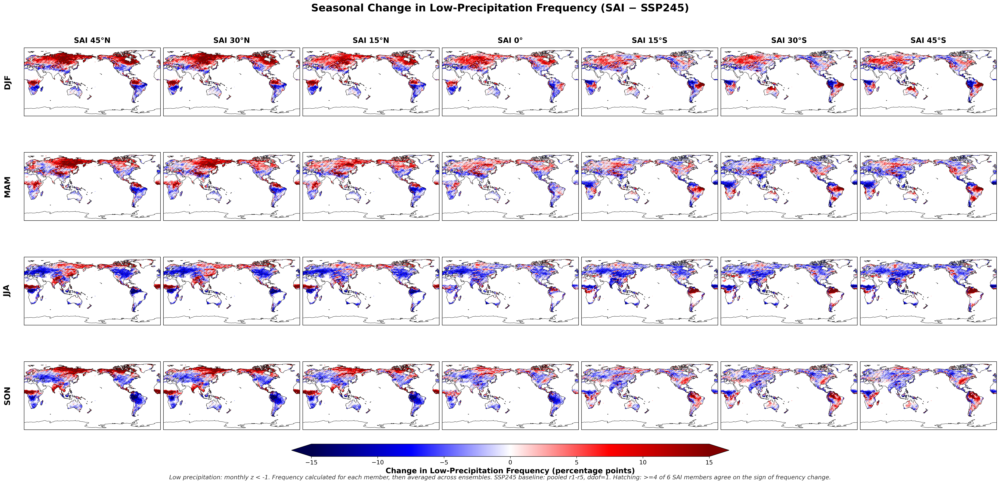


Saved figure: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_Drought_Frequency_Change_4x7_pooled5.png
Saved diagnostics: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_Drought_Frequency_Change_diagnostics_pooled5.csv

===== OVERALL SUMMARY =====
Cells within ±15 pp: 95.8%
Positive change: 40.8%
Negative change: 48.1%
Hatched cells: 79.5%

Map generation completed.


In [14]:

from pathlib import Path
import math
import csv
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# 1. SETTINGS
# ============================================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

Z_DIR = BASE_DIR / "PR_zscore_pooled5"

OUTPUT_PNG = (
    BASE_DIR / "PR_Drought_Frequency_Change_4x7_pooled5.png"
)

OUTPUT_CSV = (
    BASE_DIR / "PR_Drought_Frequency_Change_diagnostics_pooled5.csv"
)

SCENARIOS = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

SCENARIO_TITLES = [
    "45°N", "30°N", "15°N", "0°",
    "15°S", "30°S", "45°S"
]

SAI_MEMBERS = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

SSP_MEMBERS = [
    "r1", "r2", "r3", "r4", "r5"
]

SEASONS = ["DJF", "MAM", "JJA", "SON"]

SEASON_MONTHS = {
    "DJF": [12, 1, 2],
    "MAM": [3, 4, 5],
    "JJA": [6, 7, 8],
    "SON": [9, 10, 11]
}

THRESHOLD = -1.0

# Percentage points
VMIN = -15.0
VMAX = 15.0

HATCH_AGREEMENT = 2 / 3

# Require every available member to have valid frequency data
REQUIRE_ALL_MEMBERS = True

# SSP245 reference:
# Five individual members pooled across 2040-2069
# Monthly sample size = 5 members x 30 years = 150
# Sample standard deviation calculated with ddof=1

plt.rcParams["hatch.linewidth"] = 0.4
plt.rcParams["hatch.color"] = "#333333"

if not Z_DIR.is_dir():
    raise FileNotFoundError(
        f"Z-score folder not found: {Z_DIR}"
    )

# ============================================================
# 2. LOAD COMMON SPATIAL MASK
# ============================================================

MASK_CANDIDATES = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy",
]

mask_path = next(
    (p for p in MASK_CANDIDATES if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy was not found "
        "in 1118 or 1115."
    )

valid_mask = np.load(mask_path).astype(bool)

if valid_mask.shape != (192, 288):
    raise ValueError(
        f"Unexpected mask shape: {valid_mask.shape}"
    )

print("Common mask:", mask_path)
print("Valid land grid cells:", valid_mask.sum())

# ============================================================
# 3. LOAD SSP245 REFERENCE GRID
# ============================================================

reference_path = (
    BASE_DIR / "PR_SSP_ymonmean_pooled5.nc"
)

with xr.open_dataset(reference_path) as ds:
    lats = ds["lat"].values.copy()
    lons = ds["lon"].values.copy()

GRID_SHAPE = (len(lats), len(lons))

if GRID_SHAPE != valid_mask.shape:
    raise ValueError(
        f"Grid/mask mismatch: {GRID_SHAPE}"
    )

# ============================================================
# 4. FUNCTION: LOAD MONTHLY Z-SCORE
# ============================================================

def load_monthly_zscore(path):

    if not path.is_file():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        if "pr" not in ds:
            raise ValueError(
                f"Variable 'pr' not found: {path}"
            )

        da = ds["pr"].transpose(
            "time", "lat", "lon"
        )

        np.testing.assert_allclose(
            da["lat"].values,
            lats,
            err_msg=f"Latitude mismatch: {path}"
        )

        np.testing.assert_allclose(
            da["lon"].values,
            lons,
            err_msg=f"Longitude mismatch: {path}"
        )

        if da.sizes["time"] != 360:
            raise ValueError(
                f"Expected 360 months: {path}"
            )

        # Check monthly dates:
        # 2040-01 through 2069-12
        expected_years = np.repeat(
            np.arange(2040, 2070),
            12
        )

        expected_months = np.tile(
            np.arange(1, 13),
            30
        )

        years = da.time.dt.year.values
        months = da.time.dt.month.values

        if not np.array_equal(
            years, expected_years
        ):
            raise ValueError(
                f"Unexpected years: {path}"
            )

        if not np.array_equal(
            months, expected_months
        ):
            raise ValueError(
                f"Unexpected months: {path}"
            )

        values = da.values.astype(
            np.float32, copy=True
        )

    values[~np.isfinite(values)] = np.nan

    return values, months

# ============================================================
# 5. FUNCTION: SEASONAL FREQUENCY PER MEMBER
# ============================================================

def seasonal_frequency(values, months):

    """
    Each season contains 90 monthly observations
    from 2040-2069.

    For each grid cell:

        frequency =
            count(valid monthly z < -1)
            / count(valid monthly observations)

    Missing values are excluded from denominator.

    Return:
        (4, 192, 288)
        Units: percentage (%)
    """

    output = np.full(
        (4, *GRID_SHAPE),
        np.nan,
        dtype=np.float32
    )

    for i, season in enumerate(SEASONS):

        selected = np.isin(
            months,
            SEASON_MONTHS[season]
        )

        season_values = values[
            selected, :, :
        ]

        n_valid = np.sum(
            np.isfinite(season_values),
            axis=0
        )

        n_low = np.sum(
            (season_values < THRESHOLD)
            & np.isfinite(season_values),
            axis=0
        )

        output[i] = np.divide(
            n_low * 100.0,
            n_valid,
            out=np.full(
                GRID_SHAPE, np.nan,
                dtype=np.float32
            ),
            where=n_valid > 0
        )

    return output

# ============================================================
# 6. FUNCTION: MEAN ACROSS MEMBERS
# ============================================================

def member_mean(stack):

    valid_count = np.sum(
        np.isfinite(stack),
        axis=0
    )

    total = np.nansum(stack, axis=0)

    mean = np.divide(
        total,
        valid_count,
        out=np.full(
            stack.shape[1:],
            np.nan,
            dtype=np.float32
        ),
        where=valid_count > 0
    )

    return mean, valid_count

# ============================================================
# 7. SSP245 LOW-PRECIPITATION FREQUENCY
# ============================================================

print("\nLoading SSP245 monthly z-scores...")

ssp_member_frequencies = []

for member in SSP_MEMBERS:

    path = Z_DIR / (
        f"PR_zscore_monthly_SSP245_{member}.nc"
    )

    values, months = load_monthly_zscore(path)

    freq = seasonal_frequency(
        values, months
    )

    ssp_member_frequencies.append(freq)

    print(f"Loaded SSP245 {member}")

ssp_stack = np.stack(
    ssp_member_frequencies,
    axis=0
)

ssp_mean, ssp_valid_count = member_mean(
    ssp_stack
)

# Report only cells valid in all five members
ssp_complete = (
    ssp_valid_count == len(SSP_MEMBERS)
)

print("\n===== SSP245 BASELINE =====")

for i, season in enumerate(SEASONS):

    region = (
        valid_mask
        & ssp_complete[i]
        & np.isfinite(ssp_mean[i])
    )

    values = ssp_mean[i][region]

    if values.size == 0:
        raise ValueError(
            f"No valid SSP245 cells: {season}"
        )

    print(
        f"{season}: "
        f"mean={np.mean(values):.2f}%, "
        f"median={np.median(values):.2f}%, "
        f"min={np.min(values):.2f}%, "
        f"max={np.max(values):.2f}%"
    )

# ============================================================
# 8. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    4, 7,
    figsize=(28, 13),
    dpi=300,
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    },
    constrained_layout=True
)

fig.suptitle(
    "Seasonal Change in Low-Precipitation "
    "Frequency (SAI − SSP245)",
    fontsize=21,
    fontweight="bold",
    y=1.02
)

im = None
diagnostics = []

# ============================================================
# 9. PROCESS EACH SAI SCENARIO
# ============================================================

for col, scenario in enumerate(SCENARIOS):

    print("\n" + "=" * 50)
    print(f"Processing SAI {scenario}")
    print("=" * 50)

    sai_member_frequencies = []

    for member in SAI_MEMBERS:

        path = Z_DIR / (
            f"PR_zscore_monthly_{scenario}_{member}.nc"
        )

        values, months = load_monthly_zscore(path)

        freq = seasonal_frequency(
            values, months
        )

        sai_member_frequencies.append(freq)

        print(f"Loaded {scenario} {member}")

    sai_stack = np.stack(
        sai_member_frequencies,
        axis=0
    )

    n_members = sai_stack.shape[0]

    min_agreement = math.ceil(
        HATCH_AGREEMENT * n_members
    )

    # Mean frequency for SAI
    sai_mean, sai_valid_count = member_mean(
        sai_stack
    )

    # Final frequency change in percentage points
    delta = sai_mean - ssp_mean

    # Individual SAI member frequency changes
    # Relative to the same SSP245 baseline
    member_delta = (
        sai_stack - ssp_mean[None, :, :, :]
    )

    # ========================================================
    # 10. DRAW FOUR SEASONS
    # ========================================================

    for row, season in enumerate(SEASONS):

        ax = axes[row, col]

        grid_valid = (
            valid_mask
            & ssp_complete[row]
            & np.isfinite(delta[row])
        )

        # Require all SAI members for consistent comparison
        if REQUIRE_ALL_MEMBERS:
            grid_valid &= (
                sai_valid_count[row] == n_members
            )

        plotted = np.where(
            grid_valid,
            delta[row],
            np.nan
        )

        # ------------------------------
        # Hatching: sign agreement
        # ------------------------------

        changes = member_delta[:, row, :, :]

        positive = np.sum(
            changes > 0,
            axis=0
        )

        negative = np.sum(
            changes < 0,
            axis=0
        )

        agreement = np.maximum(
            positive, negative
        )

        hatch_mask = (
            grid_valid
            & (agreement >= min_agreement)
        )

        # ------------------------------
        # Draw map
        # ------------------------------

        im = ax.pcolormesh(
            lons,
            lats,
            np.clip(plotted, VMIN, VMAX),
            transform=ccrs.PlateCarree(),
            cmap="seismic",
            vmin=VMIN,
            vmax=VMAX,
            shading="auto",
            rasterized=True
        )

        ax.contourf(
            lons,
            lats,
            hatch_mask.astype(int),
            levels=[0.5, 1.5],
            hatches=["///"],
            colors="none",
            transform=ccrs.PlateCarree()
        )

        ax.add_feature(
            cfeature.COASTLINE,
            linewidth=0.5,
            edgecolor="black"
        )

        ax.set_global()

        if row == 0:
            ax.set_title(
                f"SAI {SCENARIO_TITLES[col]}",
                fontsize=15,
                fontweight="bold",
                pad=10
            )

        if col == 0:
            ax.text(
                -0.15, 0.5,
                season,
                transform=ax.transAxes,
                fontsize=16,
                fontweight="bold",
                va="center",
                rotation=90
            )

        # ------------------------------
        # Diagnostics
        # ------------------------------

        actual = plotted[
            np.isfinite(plotted)
        ]

        if actual.size == 0:
            raise ValueError(
                f"No valid cells: {scenario} {season}"
            )

        within_15 = (
            np.mean(np.abs(actual) <= 15)
            * 100
        )

        positive_pct = (
            np.mean(actual > 0) * 100
        )

        negative_pct = (
            np.mean(actual < 0) * 100
        )

        hatch_coverage = (
            np.sum(hatch_mask)
            / np.sum(grid_valid)
            * 100
        )

        diagnostics.append({
            "scenario": scenario,
            "season": season,
            "sai_members": n_members,
            "mean_change_pp": float(
                np.mean(actual)
            ),
            "median_change_pp": float(
                np.median(actual)
            ),
            "min_change_pp": float(
                np.min(actual)
            ),
            "max_change_pp": float(
                np.max(actual)
            ),
            "within_15pp_pct": float(
                within_15
            ),
            "positive_cells_pct": float(
                positive_pct
            ),
            "negative_cells_pct": float(
                negative_pct
            ),
            "hatch_coverage_pct": float(
                hatch_coverage
            )
        })

        print(
            f"{season}: "
            f"mean={np.mean(actual):+.2f} pp | "
            f"median={np.median(actual):+.2f} pp | "
            f"|change|<=15 pp: {within_15:.1f}% | "
            f"positive: {positive_pct:.1f}% | "
            f"negative: {negative_pct:.1f}% | "
            f"hatch: {hatch_coverage:.1f}%"
        )

# ============================================================
# 11. COLORBAR
# ============================================================

cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    shrink=0.45,
    aspect=35,
    pad=0.03,
    extend="both"
)

cbar.set_label(
    "Change in Low-Precipitation Frequency "
    "(percentage points)",
    fontsize=15,
    fontweight="bold"
)

cbar.ax.tick_params(labelsize=12)
cbar.set_ticks([-15, -10, -5, 0, 5, 10, 15])

# ============================================================
# 12. CAPTION
# ============================================================

fig.text(
    0.5,
    -0.01,
    "Low precipitation: monthly z < -1. "
    "Frequency calculated for each member, "
    "then averaged across ensembles. "
    "SSP245 baseline: pooled r1-r5, ddof=1. "
    "Hatching: >=4 of 6 SAI members agree "
    "on the sign of frequency change.",
    ha="center",
    fontsize=12,
    fontstyle="italic",
    color="#333333"
)

# ============================================================
# 13. SAVE FIGURE
# ============================================================

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:", OUTPUT_PNG)

# ============================================================
# 14. SAVE DIAGNOSTICS TO CSV
# ============================================================

fieldnames = [
    "scenario",
    "season",
    "sai_members",
    "mean_change_pp",
    "median_change_pp",
    "min_change_pp",
    "max_change_pp",
    "within_15pp_pct",
    "positive_cells_pct",
    "negative_cells_pct",
    "hatch_coverage_pct"
]

with open(
    OUTPUT_CSV,
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames
    )

    writer.writeheader()
    writer.writerows(diagnostics)

print("Saved diagnostics:", OUTPUT_CSV)

# ============================================================
# 15. OVERALL SUMMARY
# ============================================================

print("\n===== OVERALL SUMMARY =====")

for key, label in [
    ("within_15pp_pct", "Cells within ±15 pp"),
    ("positive_cells_pct", "Positive change"),
    ("negative_cells_pct", "Negative change"),
    ("hatch_coverage_pct", "Hatched cells"),
]:

    values = [
        d[key] for d in diagnostics
    ]

    print(
        f"{label}: "
        f"{np.mean(values):.1f}%"
    )

print("\nMap generation completed.")
